# MATH7810 Python for Data Science — Individual Case Study (AY2026/27)

**Data set:** Default of Credit Card Clients (Kaggle / UCI), file `DefaultCreditCard.csv`

> Part III (reflective essay) is a personal reflection and is left as a structured skeleton for the author to write.

# Part I — Exploratory data analysis

## 1.1 Introduction to the data set

**Background.** The file records credit card clients in Taiwan (April to September 2005). One row is one client. The original Kaggle/UCI file has 30,000 clients; this file is a random sample of 1,000 of them (the `ID` values are not consecutive). The outcome of interest is whether the client **defaulted on the next month's payment** (`default.payment.next.month`, 1 = default, 0 = no default).

**Business relevance.** A card issuer earns interest and fees from customers but loses money when they default. Knowing which clients are more likely to default helps the issuer set credit limits, decide when to send reminders or tighten credit, and price risk. All amounts are in New Taiwan dollars (NT$).

| Column | Meaning |
|---|---|
| `ID` | Client identifier. Not a measurement. |
| `LIMIT_BAL` | Amount of given credit (NT$), including individual and family/supplementary credit. |
| `SEX` | 1 = male, 2 = female. |
| `EDUCATION` | 1 = graduate school, 2 = university, 3 = high school, 4 = others, 5 = unknown, 6 = unknown. |
| `MARRIAGE` | 1 = married, 2 = single, 3 = others. (The data also contain one row coded 0, not defined in the description.) |
| `AGE` | Age in years. |
| `PAY_0`, `PAY_2` … `PAY_6` | Repayment status in September (`PAY_0`), August (`PAY_2`) … April (`PAY_6`). −1 = pay duly, 1 = payment delayed one month, 2 = delayed two months … 9 = delayed nine months or more (official Kaggle description). The data also contain the codes −2 and 0, which the description does not define (see the data checks). The file names the September column `PAY_0`; there is no `PAY_1`. |
| `BILL_AMT1` … `BILL_AMT6` | Amount of bill statement (NT$) in September … April. |
| `PAY_AMT1` … `PAY_AMT6` | Amount of previous payment (NT$) in September … April. |
| `default.payment.next.month` | Default next month (1 = yes, 0 = no). Binary outcome. |

In [1]:
import pandas as pd
import numpy as np

# One row is one client.
df = pd.read_csv("DefaultCreditCard.csv")
df = df.rename(columns={"default.payment.next.month": "default"})

print("rows, columns:", df.shape)
print("ID unique:", df["ID"].is_unique, "| duplicated rows:", int(df.duplicated().sum()))
print("total missing values:", int(df.isna().sum().sum()))
print()
print(df.dtypes.to_string())

rows, columns: (1000, 25)
ID unique: True | duplicated rows: 0
total missing values: 0

ID             int64
LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_0          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
default        int64


### Data checks and cleaning

There are no missing values and no duplicated rows. All variables are stored as numbers, but `SEX`, `EDUCATION`, `MARRIAGE` and `default` are **categorical codes** and the `PAY_*` columns are **ordinal codes** (not amounts), so they should not be averaged like measurements. Next I check the codes against the data documentation.

In [2]:
# Check the categorical codes against the documentation.
for column in ["SEX", "EDUCATION", "MARRIAGE", "default"]:
    print(column, df[column].value_counts().sort_index().to_dict())

# Negative bill amounts (a credit balance, for example after an overpayment).
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
print("\nclients with a negative bill in each month:")
print((df[bill_cols] < 0).sum().to_string())

# Repayment status codes. The description only defines -1 and 1 to 9.
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
print("\nPAY_0 codes:", df["PAY_0"].value_counts().sort_index().to_dict())
print("rows with any undocumented code (-2 or 0) in PAY_0 to PAY_6:", int(df[pay_cols].isin([-2, 0]).any(axis=1).sum()))

SEX {1: 397, 2: 603}
EDUCATION {1: 343, 2: 479, 3: 162, 4: 5, 5: 10, 6: 1}
MARRIAGE {0: 1, 1: 465, 2: 526, 3: 8}
default {0: 784, 1: 216}

clients with a negative bill in each month:
BILL_AMT1    20
BILL_AMT2    20
BILL_AMT3    16
BILL_AMT4    25
BILL_AMT5    27
BILL_AMT6    21

PAY_0 codes: {-2: 112, -1: 201, 0: 451, 1: 138, 2: 79, 3: 10, 4: 4, 6: 2, 7: 1, 8: 2}
rows with any undocumented code (-2 or 0) in PAY_0 to PAY_6: 857


**Handling.**

- `EDUCATION` has the undocumented codes 5 and 6 (and the documented 4 = "others"). They are very few (16 rows in total), so I merge 4, 5 and 6 into one category "Others/unknown". 
- `MARRIAGE` has one row coded 0, which is not in the documentation. I merge it into 3 = "Others".
- The repayment status columns contain the codes **−2 and 0**, which the official description does not define (it defines −1 = pay duly and 1 to 9 = months of delay). They are very common (about 56% of September values), so I do not delete them. Both are *smaller than 1*, so they are certainly not a payment delay. I therefore treat every `PAY_0 <= 0` as "not late" and only `PAY_0 >= 1` as late; this does not depend on what −2 and 0 exactly mean. (Discussions of this data set commonly read −2 as "no consumption" and 0 as "revolving credit, minimum payment made", but that is an unofficial reading and is not used in any test below.)
- Negative `BILL_AMT` values are kept: they are credit balances and not data errors, but I will remember that they exist when I compute statistics and correlations of bill amounts.
- I add readable label columns and a flag `late_sep` (1 if `PAY_0 >= 1`, i.e. the client was at least one month late in September).

In [3]:
df["sex_label"] = df["SEX"].map({1: "Male", 2: "Female"})
df["edu_label"] = df["EDUCATION"].map({1: "Graduate school", 2: "University", 3: "High school"}).fillna("Others/unknown")
df["marriage_label"] = df["MARRIAGE"].map({1: "Married", 2: "Single"}).fillna("Others")
df["late_sep"] = (df["PAY_0"] >= 1).astype(int)

# Repayment status in September grouped for the later plots.
def pay_group(x):
    if x <= -1:
        return "Code -2 or -1\n(not late)"
    if x == 0:
        return "Code 0\n(not late)"
    if x == 1:
        return "1 month\nlate"
    if x == 2:
        return "2 months\nlate"
    return "3+ months\nlate"
df["pay_group"] = df["PAY_0"].apply(pay_group)

print(df["edu_label"].value_counts().to_string())
print()
print(df["marriage_label"].value_counts().to_string())
print()
print("late in September (PAY_0 >= 1):", int(df["late_sep"].sum()), "clients")

edu_label
University         479
Graduate school    343
High school        162
Others/unknown      16

marriage_label
Single     526
Married    465
Others       9

late in September (PAY_0 >= 1): 236 clients


## 1.2 Numerical descriptive statistics

### Categorical variables

In [4]:
# Count and percentage for each category.
for column in ["sex_label", "edu_label", "marriage_label", "default"]:
    counts = df[column].value_counts()
    table = pd.DataFrame({"count": counts, "percentage": (100 * counts / len(df)).round(1)})
    print(column)
    print(table.to_string())
    print()

sex_label
           count  percentage
sex_label                   
Female       603        60.3
Male         397        39.7

edu_label
                 count  percentage
edu_label                         
University         479        47.9
Graduate school    343        34.3
High school        162        16.2
Others/unknown      16         1.6

marriage_label
                count  percentage
marriage_label                   
Single            526        52.6
Married           465        46.5
Others              9         0.9

default
         count  percentage
default                   
0          784        78.4
1          216        21.6



### Numerical variables

The five-number summary is shown together with the sample mean and standard deviation. The same quartiles are then used to flag outliers with the rule Q1 − 1.5 × IQR and Q3 + 1.5 × IQR.

In [5]:
numeric = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
summary = df[numeric].quantile([0, 0.25, 0.5, 0.75, 1]).T
summary.columns = ["Minimum", "Q1", "Median", "Q3", "Maximum"]
summary.insert(0, "Std dev", df[numeric].std().values)
summary.insert(0, "Mean", df[numeric].mean().values)
print(summary.round(1).to_string())

# Outliers by the 1.5 x IQR rule.
rows = []
for column in numeric:
    values = df[column]
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((values < lower) | (values > upper)).sum())
    rows.append([column, round(lower, 1), round(upper, 1), n_out, round(100 * n_out / len(values), 1)])
print()
print(pd.DataFrame(rows, columns=["variable", "lower fence", "upper fence", "outliers", "percentage"]).to_string(index=False))

               Mean   Std dev  Minimum       Q1    Median        Q3   Maximum
LIMIT_BAL  174080.0  132714.6  10000.0  60000.0  150000.0  250000.0  680000.0
AGE            35.4       9.4     21.0     28.0      34.0      41.0      66.0
BILL_AMT1   51341.7   74935.4  -9095.0   2902.5   20952.5   68287.8  568532.0
PAY_AMT1     5942.8   15732.9      0.0    861.8    2100.0    5253.0  244500.0

 variable  lower fence  upper fence  outliers  percentage
LIMIT_BAL    -225000.0     535000.0         5         0.5
      AGE          8.5         60.5        13         1.3
BILL_AMT1     -95175.4     166365.6        76         7.6
 PAY_AMT1      -5725.1      11839.9        87         8.7


**Reading the table.** The mean of `LIMIT_BAL` (about NT$174,000) is above its median (NT$150,000), and the means of `BILL_AMT1` and `PAY_AMT1` are far above their medians, so these three variables are **right-skewed**. `PAY_AMT1` has the largest relative spread: its standard deviation is about 2.6 times its mean, and a few clients pay more than NT$200,000 in one month. For these skewed variables the median describes a "typical" client better than the mean. The outliers are real, large customers rather than recording errors, so I do **not** delete them; I check later that the main conclusions do not depend on them. `AGE` is roughly symmetric, with a typical client in the mid-30s.

### Default rate overall and by group

In [6]:
from scipy import stats

n = len(df)
p_hat = df["default"].mean()
se = np.sqrt(p_hat * (1 - p_hat) / n)
z = stats.norm.ppf(0.975)
print(f"overall default rate: {p_hat:.3f}  (n = {n})")
print(f"95% z interval: ({p_hat - z*se:.3f}, {p_hat + z*se:.3f})")
print()
for column in ["sex_label", "edu_label", "marriage_label", "pay_group"]:
    table = df.groupby(column)["default"].agg(["count", "sum", "mean"])
    table.columns = ["clients", "defaults", "default rate"]
    print(table.rename(index=lambda s: str(s).replace("\n", " ")).round(3).to_string())
    print()

overall default rate: 0.216  (n = 1000)
95% z interval: (0.190, 0.242)

           clients  defaults  default rate
sex_label                                 
Female         603       124         0.206
Male           397        92         0.232

                 clients  defaults  default rate
edu_label                                       
Graduate school      343        55         0.160
High school          162        47         0.290
Others/unknown        16         1         0.062
University           479       113         0.236

                clients  defaults  default rate
marriage_label                                 
Married             465       107         0.230
Others                9         3         0.333
Single              526       106         0.202

                          clients  defaults  default rate
pay_group                                                
1 month late                  138        46         0.333
2 months late                  79        53  

### Correlation between numerical variables

The sample correlation $r=\dfrac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2\sum (y_i-\bar y)^2}}$ measures the strength of a **linear** association. Spearman's rank correlation is added as a check because the variables are skewed.

In [7]:
print("Pearson correlation")
print(df[numeric].corr().round(3).to_string())
print()
print("Spearman rank correlation")
print(df[numeric].corr(method="spearman").round(3).to_string())

Pearson correlation
           LIMIT_BAL    AGE  BILL_AMT1  PAY_AMT1
LIMIT_BAL      1.000  0.187      0.255     0.233
AGE            0.187  1.000      0.019     0.043
BILL_AMT1      0.255  0.019      1.000     0.127
PAY_AMT1       0.233  0.043      0.127     1.000

Spearman rank correlation
           LIMIT_BAL    AGE  BILL_AMT1  PAY_AMT1
LIMIT_BAL      1.000  0.218     -0.022     0.233
AGE            0.218  1.000     -0.076    -0.041
BILL_AMT1     -0.022 -0.076      1.000     0.441
PAY_AMT1       0.233 -0.041      0.441     1.000


**Interpretation (association is not causation).** All correlations among these four variables are weak to moderate. The strongest are `LIMIT_BAL` with `BILL_AMT1` (Pearson r ≈ 0.26) and with `PAY_AMT1` (r ≈ 0.23): clients with higher limits tend to have larger bills and make larger payments, which is plausible because they can spend more. Note that the Pearson and Spearman values for `LIMIT_BAL` and `BILL_AMT1` **disagree strongly** (Spearman is close to 0), which shows that the Pearson correlation is driven by a small number of very large bills and not by a general pattern. `AGE` is hardly related to bills or payments.

## 1.3 Exploratory analysis with visualizations

### 1.3.1 Default rate by September repayment status

pay_group
Code -2 or -1 (not late)    15.0
Code 0 (not late)           13.1
1 month late                33.3
2 months late               67.1
3+ months late              57.9


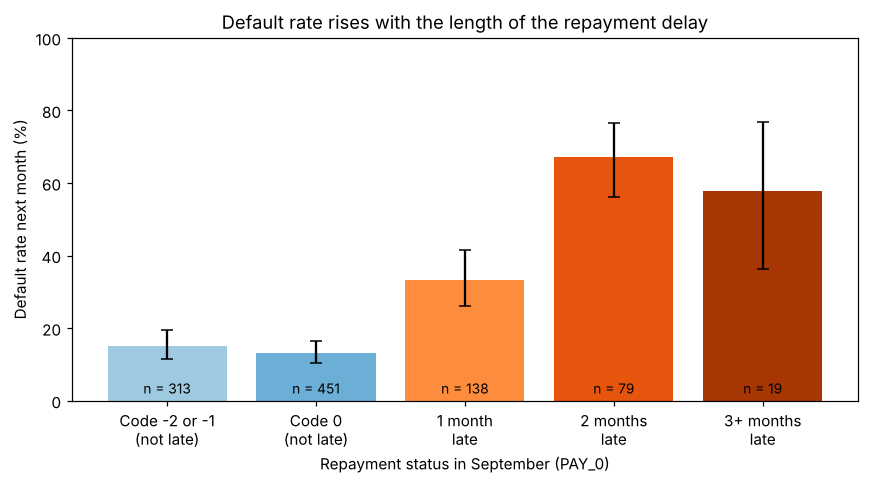

In [8]:
import matplotlib.pyplot as plt

def wilson(k, n, conf=0.95):
    # Wilson score interval for a proportion (more reliable than the normal interval for small groups).
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

order = ["Code -2 or -1\n(not late)", "Code 0\n(not late)", "1 month\nlate", "2 months\nlate", "3+ months\nlate"]
g = df.groupby("pay_group")["default"].agg(["sum", "count"]).reindex(order)
rate = g["sum"] / g["count"]
ci = np.array([wilson(k, m) for k, m in zip(g["sum"], g["count"])])
err = np.vstack([rate - ci[:, 0], ci[:, 1] - rate])

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(order, 100 * rate, yerr=100 * err, capsize=4, color=["#9ecae1", "#6baed6", "#fd8d3c", "#e6550d", "#a63603"])
for bar, m in zip(bars, g["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, 2, f"n = {m}", ha="center", fontsize=9, color="black")
ax.set_ylabel("Default rate next month (%)")
ax.set_xlabel("Repayment status in September (PAY_0)")
ax.set_title("Default rate rises with the length of the repayment delay")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()
print((100 * rate).rename(index=lambda s: s.replace("\n", " ")).round(1).to_string())

**Interpretation.** The default rate is about 15% for clients with code −2 or −1 and about 13% for clients with code 0; neither group is late, and their rates are similar. It rises to 33% for clients one month late and to 67% for clients two months late. The 3+ months bar (58%) rests on only 19 clients and its wide interval overlaps the 2-month bar, so we cannot conclude that it is lower. Repayment delay is clearly associated with default, and this motivates Research Question 2.

**Business implication.** The most recent repayment status is a cheap and powerful early-warning signal. The bank can put clients who are already one month late into a reminder or collection programme *before* the next due date, and can review credit limits for clients with two or more months of delay.

### 1.3.2 Credit limit and default

             mean    median
default                    
0        185217.0  160000.0
1        133657.0   95000.0


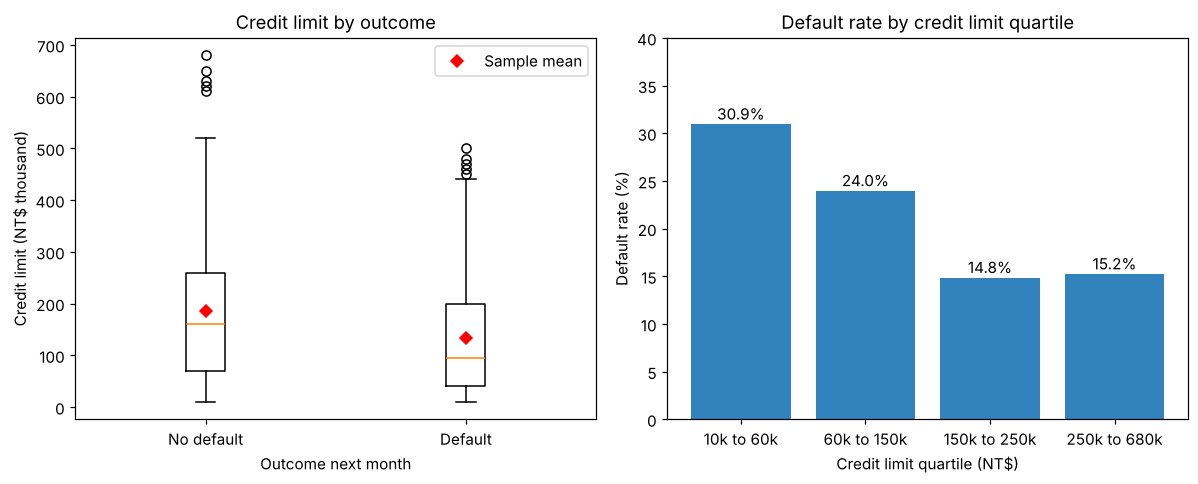

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: boxplot of the credit limit for each outcome, with the sample mean as a diamond.
labels = ["No default", "Default"]
groups = [df.loc[df["default"] == k, "LIMIT_BAL"] / 1000 for k in [0, 1]]
axes[0].boxplot(groups)
axes[0].plot([1, 2], [g.mean() for g in groups], "D", color="red", label="Sample mean")
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Credit limit (NT$ thousand)")
axes[0].set_xlabel("Outcome next month")
axes[0].set_title("Credit limit by outcome")
axes[0].legend()

# Right: default rate by credit limit quartile.
quartile = pd.qcut(df["LIMIT_BAL"], 4)
rates = df.groupby(quartile, observed=True)["default"].agg(["mean", "count"])
names = [f"{int(i.left/1000) if i.left > 10000 else 10}k to {int(i.right/1000)}k" for i in rates.index]
axes[1].bar(names, 100 * rates["mean"], color="#3182bd")
for x, (m, c) in enumerate(zip(rates["mean"], rates["count"])):
    axes[1].text(x, 100 * m + 0.5, f"{100*m:.1f}%", ha="center")
axes[1].set_xlabel("Credit limit quartile (NT$)")
axes[1].set_ylabel("Default rate (%)")
axes[1].set_ylim(0, 40)
axes[1].set_title("Default rate by credit limit quartile")
plt.tight_layout()
plt.show()
print(df.groupby("default")["LIMIT_BAL"].agg(["mean", "median"]).round(0).to_string())

**Interpretation.** Defaulters have a lower credit limit: the median is NT$95,000 against NT$160,000 for non-defaulters, and the mean is about NT$134,000 against NT$185,000. The right panel shows the same pattern: 30.9% of clients in the lowest limit quartile defaulted, 24.0% in the second quartile, and about 15% in each of the two top quartiles. The risk falls as the limit rises and then levels off.

**Business implication.** Clients with small limits are the riskiest group, so a low limit is not a safe way of controlling losses by itself; the bank may want to look at how limits are granted and monitored at the low end. It also motivates Research Question 1 in Part II.

### 1.3.3 Credit limit and September bill

Pearson r = 0.255, Spearman = -0.022
clients whose September bill exceeds the credit limit: 86


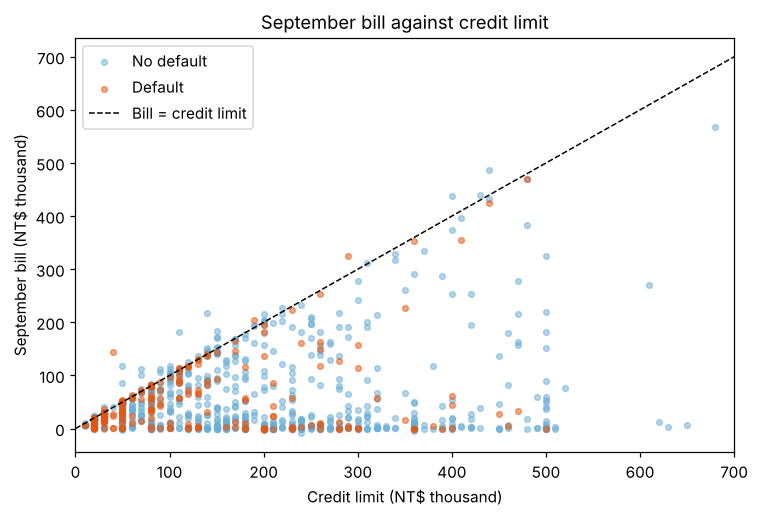

In [10]:
r_pearson = df["LIMIT_BAL"].corr(df["BILL_AMT1"])
r_spearman = df["LIMIT_BAL"].corr(df["BILL_AMT1"], method="spearman")
print(f"Pearson r = {r_pearson:.3f}, Spearman = {r_spearman:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.8))
for k, color, name in [(0, "#6baed6", "No default"), (1, "#e6550d", "Default")]:
    sub = df[df["default"] == k]
    ax.scatter(sub["LIMIT_BAL"] / 1000, sub["BILL_AMT1"] / 1000, s=14, alpha=0.5, color=color, label=name)
ax.plot([0, 700], [0, 700], "k--", lw=1, label="Bill = credit limit")
ax.set_xlim(0, 700)
ax.set_xlabel("Credit limit (NT$ thousand)")
ax.set_ylabel("September bill (NT$ thousand)")
ax.set_title("September bill against credit limit")
ax.legend()
plt.tight_layout()
plt.show()

over = int((df["BILL_AMT1"] > df["LIMIT_BAL"]).sum())
print("clients whose September bill exceeds the credit limit:", over)

**Interpretation.** Most clients have a September bill far below their limit, and many are near zero (they pay in full or barely use the card). A visible group lies on or just below the dashed line, that is, they use their whole limit; this is especially common at limits below NT$150,000, and 86 clients (8.6%) have a bill above their limit. Orange points (defaults) appear along the dashed line at low limits more often than among the low-bill clients. The overall pattern is not a clean straight line, which is consistent with the gap between Pearson r (0.26) and Spearman (−0.02) found in Section 1.2.

**Business implication.** Utilisation (bill divided by limit) is a more informative risk feature than the raw bill amount. Clients close to or above the dashed line are using all of their credit and deserve monitoring.

### 1.3.4 Default rate by education and sex

sex_label        Female  Male
edu_label                    
Graduate school    13.9  19.0
University         22.5  25.4
High school        29.7  28.2
Others/unknown     11.1   0.0

sex_label        Female  Male
edu_label                    
Graduate school     201   142
University          302   177
High school          91    71
Others/unknown        9     7


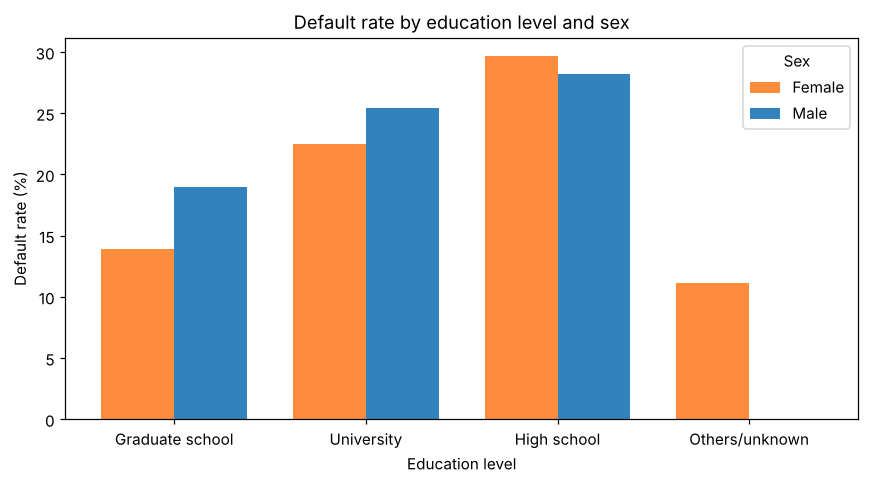

In [11]:
edu_order = ["Graduate school", "University", "High school", "Others/unknown"]
table = df.pivot_table(index="edu_label", columns="sex_label", values="default", aggfunc="mean").reindex(edu_order) * 100
counts = df.pivot_table(index="edu_label", columns="sex_label", values="default", aggfunc="count").reindex(edu_order)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(edu_order))
w = 0.38
ax.bar(x - w / 2, table["Female"], w, label="Female", color="#fd8d3c")
ax.bar(x + w / 2, table["Male"], w, label="Male", color="#3182bd")
ax.set_xticks(x)
ax.set_xticklabels(edu_order)
ax.set_xlabel("Education level")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by education level and sex")
ax.legend(title="Sex")
plt.tight_layout()
plt.show()
print(table.round(1).to_string())
print()
print(counts.to_string())

**Interpretation.** Default falls as education rises: 16.0% for graduate school, 23.6% for university and 29.0% for high school overall. Within each of these three levels the sexes are close; men are a little higher at graduate and university level and women a little higher/equal at high school, so there is no consistent gender pattern. The "Others/unknown" bars rest on 9 women and 7 men and carry almost no information.

**Business implication.** Education may be associated with risk, but the groups are small after splitting by sex, so differences should not be over-interpreted. Also, using sex directly in credit decisions is ethically and legally problematic in many jurisdictions; behavioural variables (repayment history, utilisation) are better and fairer bases for decisions.

# Part II — Research questions and statistical analysis

## 2.1 Three research questions proposed by the author (without AI)

#### 2.1.1 Credit limit of defaulters and non-defaulters
Is the mean credit limit (`LIMIT_BAL`) different for clients who default and clients who do not?

*Why it matters / feasibility:* The credit limit is the one risk lever the bank directly controls. If defaulters have a different average limit, the limit-setting policy is related to risk. It can be answered with a two-sample test for means because `LIMIT_BAL` is numerical and `default` splits the sample into two independent groups.

#### 2.1.2 Default rate for clients who are late and not late
Is the proportion of defaults higher among clients who were late in September (`PAY_0 >= 1`) than among clients who were not late?

*Why it matters / feasibility:* If late clients default far more often, a late payment is a practical early-warning trigger for collection actions. Both variables are binary, so a two-proportion z-test and interval fit.

#### 2.1.3 Default rate for men and women
Is the default proportion the same for male and female clients?

*Why it matters / feasibility:* It checks whether a gender gap exists in this portfolio (for fairness monitoring and portfolio understanding). It is also a two-proportion problem.

## 2.2 Three research questions proposed by AI

<span style="color:red">**Prompt:** paste the exact prompt that you gave to your AI tool here. (For example: "I have a random sample of 1,000 credit card clients with credit limit, sex, education, marriage, age, six months of repayment status, bill and payment amounts, and a binary default indicator. Propose three business-relevant research questions that I can answer with confidence intervals, hypothesis tests, correlation or simple linear regression.")</span>

<span style="color:red">Replace the three questions below with exactly what your AI tool returned. The three below are given as an example of this kind of output.</span>

#### 2.2.1 What is the overall default rate?
Estimate the population default proportion with a 95% z confidence interval.

#### 2.2.2 Is credit limit linearly related to age?
Fit a simple linear regression of `LIMIT_BAL` on `AGE` and test whether the slope is different from 0.

#### 2.2.3 Do defaulters have a different mean September bill?
Compare mean `BILL_AMT1` between defaulters and non-defaulters with a Welch t-test.

## 2.3 Comparison and final research questions

| Final question | Source | Why kept |
|---|---|---|
| **Q1** Mean credit limit of defaulters vs non-defaulters | Mainly **me** (my 2.1.1) | Credit limit is the lever the bank controls; `LIMIT_BAL` is complete and numerical; the Part I plots already hint at a difference. AI's 2.2.3 has the same structure but `BILL_AMT1` is highly skewed and contains negative values, so the mean is a poor summary there. |
| **Q2** Default rate for late vs not late clients | **Merge**: my 2.1.2 for the question and test, plus the AI's idea (2.2.1) of reporting an interval estimate | A test alone only says "different"; a confidence interval for the difference tells the bank how large the gap is. |
| **Q3** Linear relationship between age and credit limit | Mainly **AI** (2.2.2) | It adds a regression analysis that my own list did not include, and answers a limit-setting question (do older clients receive higher limits?). I dropped my 2.1.3 (default rate by sex) because it is the weakest business question: sex should not drive credit decisions, so the answer is hard to act on. |

I checked the feasibility of each final question: all needed variables are complete, the groups are large enough (the smallest group in Q2 has 236 clients), and the methods are from the course.

## Research question 1: Mean credit limit of defaulters and non-defaulters

**Hypotheses.** Let $\mu_1$ be the mean credit limit of clients who default and $\mu_0$ that of clients who do not.

$H_0:\ \mu_1=\mu_0 \qquad H_1:\ \mu_1\neq\mu_0 \qquad (\alpha=0.05)$

**Test and statistic.** Welch's two-sample t-test (independent groups, population standard deviations unknown and possibly unequal):

$$t=\frac{\bar x_1-\bar x_0}{\sqrt{\dfrac{s_1^2}{n_1}+\dfrac{s_0^2}{n_0}}},\qquad df\approx\frac{\left(\frac{s_1^2}{n_1}+\frac{s_0^2}{n_0}\right)^2}{\frac{(s_1^2/n_1)^2}{n_1-1}+\frac{(s_0^2/n_0)^2}{n_0-1}}$$

**Why this test.** The two groups are different clients (independent), the outcome is numerical, and the sample standard deviations differ (about 116k vs 135k), so Welch's version, which does not assume equal variances, is safer than the pooled t-test. `LIMIT_BAL` is right-skewed, but both groups are large (216 and 784), so by the central limit theorem the sample means are approximately normal. As a robustness check I also run the Mann–Whitney test, which does not rely on normality.

In [12]:
d1 = df.loc[df["default"] == 1, "LIMIT_BAL"]
d0 = df.loc[df["default"] == 0, "LIMIT_BAL"]
n1, n0 = len(d1), len(d0)
m1, m0 = d1.mean(), d0.mean()
v1, v0 = d1.var(ddof=1) / n1, d0.var(ddof=1) / n0

t_stat = (m1 - m0) / np.sqrt(v1 + v0)
dof = (v1 + v0) ** 2 / (v1**2 / (n1 - 1) + v0**2 / (n0 - 1))
p_value = 2 * stats.t.sf(abs(t_stat), dof)
half = stats.t.ppf(0.975, dof) * np.sqrt(v1 + v0)

print(f"default:     n = {n1}, mean = {m1:,.0f}, sd = {d1.std():,.0f}")
print(f"no default:  n = {n0}, mean = {m0:,.0f}, sd = {d0.std():,.0f}")
print(f"difference in means = {m1 - m0:,.0f}")
print(f"Welch t = {t_stat:.3f}, df = {dof:.1f}, p-value = {p_value:.2e}")
print(f"95% CI for mu1 - mu0: ({m1 - m0 - half:,.0f}, {m1 - m0 + half:,.0f})")

# Check against scipy, and a rank-based robustness check.
check = stats.ttest_ind(d1, d0, equal_var=False)
print(f"scipy Welch: t = {check.statistic:.3f}, p = {check.pvalue:.2e}")
mw = stats.mannwhitneyu(d1, d0, alternative="two-sided")
print(f"Mann-Whitney U p-value = {mw.pvalue:.2e}")

default:     n = 216, mean = 133,657, sd = 115,995
no default:  n = 784, mean = 185,217, sd = 134,917
difference in means = -51,559
Welch t = -5.576, df = 390.3, p-value = 4.61e-08
95% CI for mu1 - mu0: (-69,740, -33,379)
scipy Welch: t = -5.576, p = 4.61e-08
Mann-Whitney U p-value = 4.01e-08


**Result.** Clients who default have a mean credit limit about NT$51,600 lower than clients who do not (≈ NT$133,700 vs ≈ NT$185,200). Welch's test gives t ≈ −5.58 with about 390 degrees of freedom and a p-value of about 5 × 10⁻⁸, far below 0.05, so we **reject H₀**. The 95% confidence interval for μ₁ − μ₀ is roughly (−NT$69,700, −NT$33,400); it excludes 0. The Mann–Whitney test agrees (p ≈ 4 × 10⁻⁸), so the conclusion does not depend on the skewness or the outliers.

**Business interpretation.** In this sample, defaulting clients had clearly lower credit limits than clients who paid. Based on this we can say that low-limit clients are a higher-risk segment, and the size of the gap (tens of thousands of NT$) is large relative to the typical limit. This is an association: a low limit may be a *signal* of lower income or a weaker credit history that the bank already used when granting the limit; it does not mean that lowering a limit makes someone default, and raising limits would not by itself reduce defaults.

## Research question 2: Default rate for late and not late clients

**Hypotheses.** Let $p_1$ be the default proportion among clients who were late in September (`PAY_0 >= 1`) and $p_2$ the proportion among clients who were not.

$H_0:\ p_1=p_2 \qquad H_1:\ p_1\neq p_2 \qquad (\alpha=0.05)$

**Test and statistic.** Two-proportion z-test with the pooled proportion $\hat p=\dfrac{x_1+x_2}{n_1+n_2}$:

$$z=\frac{\hat p_1-\hat p_2}{\sqrt{\hat p(1-\hat p)\left(\frac1{n_1}+\frac1{n_2}\right)}}$$

and the (unpooled) 95% confidence interval for the difference $(\hat p_1-\hat p_2)\pm 1.96\sqrt{\frac{\hat p_1(1-\hat p_1)}{n_1}+\frac{\hat p_2(1-\hat p_2)}{n_2}}$.

**Why this test.** The outcome is binary, the two groups are independent samples of different clients, and the sample is large: the counts of defaults and non-defaults in each group (checked below) are all at least 10, so the normal approximation is appropriate.

In [13]:
late = df[df["late_sep"] == 1]["default"]
ontime = df[df["late_sep"] == 0]["default"]
x1, n1 = late.sum(), len(late)
x2, n2 = ontime.sum(), len(ontime)
p1, p2 = x1 / n1, x2 / n2

# Success/failure counts for the normal approximation.
print("defaults / non-defaults, late:    ", x1, n1 - x1)
print("defaults / non-defaults, not late:", x2, n2 - x2)

p_pool = (x1 + x2) / (n1 + n2)
z_stat = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_value = 2 * stats.norm.sf(abs(z_stat))

se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
lo, hi = (p1 - p2) - 1.96 * se_diff, (p1 - p2) + 1.96 * se_diff

print(f"\nlate:     p1 = {p1:.3f}  (n = {n1})")
print(f"not late: p2 = {p2:.3f}  (n = {n2})")
print(f"difference = {p1 - p2:.3f}, ratio p1/p2 = {p1 / p2:.2f}")
print(f"z = {z_stat:.3f}, p-value = {p_value:.2e}")
print(f"95% CI for p1 - p2: ({lo:.3f}, {hi:.3f})")

# Cross-check with a chi-square test of independence (same test for a 2x2 table).
table = pd.crosstab(df["late_sep"], df["default"])
chi2 = stats.chi2_contingency(table, correction=False)
print(f"chi-square check: chi2 = {chi2[0]:.2f} (= z^2 = {z_stat**2:.2f}), p = {chi2[1]:.2e}")

defaults / non-defaults, late:     110 126
defaults / non-defaults, not late: 106 658

late:     p1 = 0.466  (n = 236)
not late: p2 = 0.139  (n = 764)
difference = 0.327, ratio p1/p2 = 3.36
z = 10.682, p-value = 1.24e-26
95% CI for p1 - p2: (0.259, 0.396)
chi-square check: chi2 = 114.10 (= z^2 = 114.10), p = 1.24e-26


**Result.** 46.6% of the late clients (110 of 236) defaulted, against 13.9% of the clients who were not late (106 of 764). The difference is 32.7 percentage points; z ≈ 10.7 and the p-value is essentially 0, so we **reject H₀**. The 95% confidence interval for $p_1-p_2$ is about (25.9, 39.6) percentage points, so even the low end of the interval shows a large gap. A late client is about 3.4 times as likely to default as an on-time client. The chi-square test of independence gives the same conclusion (χ² = z²).

**Business interpretation.** A payment that is at least one month late in September is a strong warning sign for default in October: roughly every second late client defaulted compared with about one in seven among the others. A simple rule ("contact every client who has just become one month late") would reach a group with a default rate more than three times the average, so collection effort can be targeted effectively. The result describes association in this sample; it does not tell how much a reminder would reduce defaults, and about half of the late clients still did not default, so the rule alone will produce many false alarms.

## Research question 3: Is credit limit linearly related to age?

**Model.** $\text{LIMIT\_BAL}_i=\beta_0+\beta_1\,\text{AGE}_i+\varepsilon_i$, with $\varepsilon_i$ independent, mean 0 and constant variance.

**Hypotheses.** $H_0:\ \beta_1=0$ (no linear relationship) $\qquad H_1:\ \beta_1\neq0 \qquad (\alpha=0.05)$

**Test and statistic.** t-test for the slope with $n-2$ degrees of freedom:

$$t=\frac{b_1}{SE(b_1)},\qquad b_1=\frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sum(x_i-\bar x)^2},\qquad SE(b_1)=\frac{s_e}{\sqrt{\sum(x_i-\bar x)^2}}$$

The 95% confidence interval for the slope is $b_1\pm t_{0.975,\,n-2}\,SE(b_1)$, and $R^2=r^2$ is the proportion of the variation in the credit limit explained by age.

**Why this test.** Both variables are numerical and the question is about the average change in the limit per year of age. The t-test on the slope is equivalent to testing whether the correlation is 0. The conditions (linearity, independent errors, roughly constant variance, approximately normal residuals) are checked with the residual plots below.

fitted line: LIMIT_BAL = 80,962 + 2,629.6 * AGE
slope SE = 438.3, t = 6.00, df = 998, p-value = 2.78e-09
95% CI for slope: (1,769, 3,490)
r = 0.187, R^2 = 0.035
Spearman rank correlation = 0.218 (robustness check)


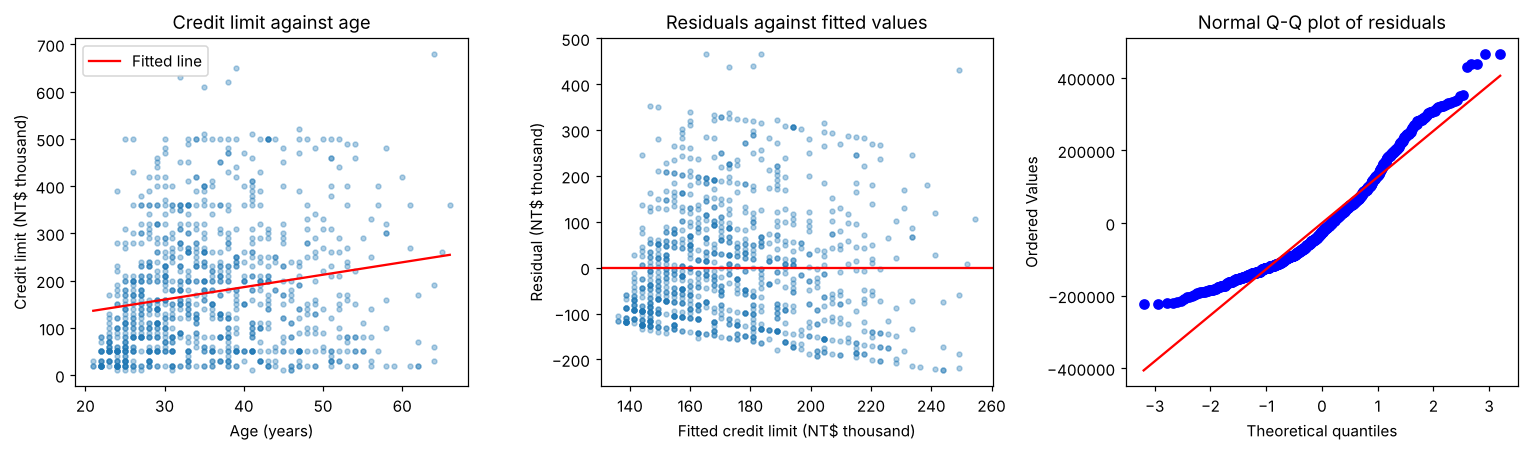

In [14]:
x = df["AGE"]
y = df["LIMIT_BAL"]
fit = stats.linregress(x, y)
n = len(df)
t_crit = stats.t.ppf(0.975, n - 2)
t_slope = fit.slope / fit.stderr

print(f"fitted line: LIMIT_BAL = {fit.intercept:,.0f} + {fit.slope:,.1f} * AGE")
print(f"slope SE = {fit.stderr:,.1f}, t = {t_slope:.2f}, df = {n - 2}, p-value = {fit.pvalue:.2e}")
print(f"95% CI for slope: ({fit.slope - t_crit * fit.stderr:,.0f}, {fit.slope + t_crit * fit.stderr:,.0f})")
print(f"r = {fit.rvalue:.3f}, R^2 = {fit.rvalue**2:.3f}")
print(f"Spearman rank correlation = {stats.spearmanr(x, y).statistic:.3f} (robustness check)")

fitted = fit.intercept + fit.slope * x
resid = y - fitted
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].scatter(x, y / 1000, s=10, alpha=0.35)
xs = np.linspace(x.min(), x.max(), 100)
axes[0].plot(xs, (fit.intercept + fit.slope * xs) / 1000, color="red", label="Fitted line")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Credit limit (NT$ thousand)")
axes[0].set_title("Credit limit against age")
axes[0].legend()
axes[1].scatter(fitted / 1000, resid / 1000, s=10, alpha=0.35)
axes[1].axhline(0, color="red")
axes[1].set_xlabel("Fitted credit limit (NT$ thousand)")
axes[1].set_ylabel("Residual (NT$ thousand)")
axes[1].set_title("Residuals against fitted values")
stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q plot of residuals")
plt.tight_layout()
plt.show()

**Result.** The fitted line is LIMIT_BAL ≈ 80,962 + 2,630 × AGE. The slope has t ≈ 6.0 (998 degrees of freedom) and a p-value of about 3 × 10⁻⁹, so we **reject H₀**. The 95% confidence interval for the slope is about (NT$1,770, NT$3,490) per year of age. The correlation is r ≈ 0.19 and R² ≈ 0.035, and Spearman's rank correlation (≈ 0.22) gives the same direction, so the result is not caused by a few outliers.

**Checking the conditions.** The residual plot shows no strong fan shape, so the constant-variance condition looks acceptable, but the residuals are asymmetric: they stop at about −NT$200,000 (a limit cannot go below zero) and have a long upper tail. The Q-Q plot confirms right-skewed residuals, so the normality condition is only approximate. With n = 1,000 the t-test for the slope is still reasonably reliable, and the rank check agrees, but the standard error and interval should be read as approximate.

**Business interpretation.** Older clients tend to have higher credit limits: each additional year of age is associated with about NT$2,600 more limit on average. However, age explains only about 3.5% of the variation in limits, so it is a weak predictor of any single client's limit; income, credit history and other factors must matter much more. The relationship is also not a straight line over the whole range: the average limit rises from the twenties to the thirties and then is roughly flat, so the issuer should be careful about extrapolating a single slope. The statistical significance should not be confused with practical importance, and this is an association, not proof that age *causes* higher limits.

# Part III — Human–AI partnership reflective essay (≥ 400 words)

<span style="color:red">**This part must be written by you from your own experience.** It is graded on your own reflection, so I have not written it. The skeleton below follows the assignment; delete the red notes when you write.</span>

## 1. Learning Python when AI can generate code

<span style="color:red">Write: your Python experience before this course; whether you doubted that learning Python is still necessary; how you see it now after using Copilot in labs and in this case study.</span>

## 2. The environment you worked in

<span style="color:red">Write: whether you had used an IDE before; whether Codespaces felt overwhelming, convenient or both; one part that was challenging; one IDE feature you found most useful and why.</span>

## 3. Your judgement in this case study

### 3.1 A working belief you tested

<span style="color:red">Write one belief you actually held, the check you used, what you found, whether you changed your mind, and why it matters. Examples of evidence that appears in this notebook (use one only if it matches what really happened to you):
- *Belief about the data:* "the mean credit limit/bill is a fair picture of a typical client." Check: the five-number summary and outliers table show mean ≫ median for `BILL_AMT1` and `PAY_AMT1`.
- *Belief about the pattern:* "clients with bigger bills are the bigger-limit clients, and the correlation shows it." Check: Pearson r ≈ 0.26 but Spearman ≈ 0 for `LIMIT_BAL` vs `BILL_AMT1`.
- *Belief about the method:* "a normal-based test is fine for skewed data." Check: Mann–Whitney robustness test in Research Question 1.</span>

### 3.2 A Copilot suggestion you evaluated

<span style="color:red">Write one suggestion not already used in Part II: what you asked, what Copilot suggested, how you checked it, what you kept or changed and why.</span>

### 3.3 Overall effect of Copilot on speed and confidence

<span style="color:red">Write your own overall assessment.</span>

# Part IV — References

1. Kaggle. *Default of Credit Card Clients Dataset* (UCI Machine Learning). https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset
2. UCI Machine Learning Repository. *Default of Credit Card Clients*. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
3. Yeh, I. C., & Lien, C. H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications*, 36(2), 2473–2480.
4. SciPy documentation: `scipy.stats` (`ttest_ind`, `mannwhitneyu`, `linregress`, `chi2_contingency`). https://docs.scipy.org/doc/scipy/reference/stats.html
5. pandas documentation. https://pandas.pydata.org/docs/
6. Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209–212.
7. MATH7810 course lecture notes and the Week 08 structural demo notebook.